GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'fake-and-real-news-dataset' dataset.
Articles: 44898 | Fake: 23481 | Real: 21417
After cleaning: 39094
Train: 27365 Val: 5864 Test: 5865


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 300)       │          0 │ input_layer[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 300, 64)   │  1,280,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 300)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      4,128 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,350,209 (5.15 MB)

 Trainable params: 1,350,209 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
428/428 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.9514 - loss: 0.1098 - val_accuracy: 0.9923 - val_loss: 0.0224
Epoch 2/6
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9961 - loss: 0.0133 - val_accuracy: 0.9901 - val_loss: 0.0342
Epoch 3/6
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.9984 - loss: 0.0048 - val_accuracy: 0.9901 - val_loss: 0.0358


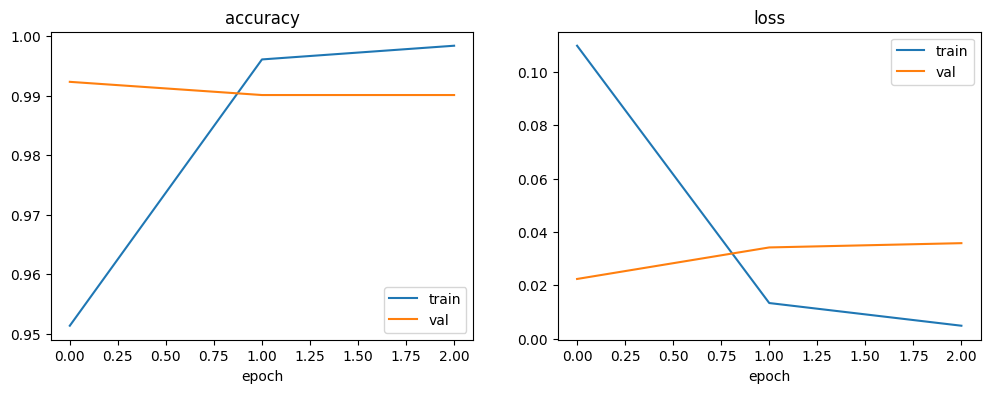

92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9889 - loss: 0.0295
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step

===== FINAL TEST RESULTS =====
Accuracy : 0.9889
Precision: 0.9827
Recall   : 0.9933
F1-score : 0.9880

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Real     0.9943    0.9852    0.9897      3180
        Fake     0.9827    0.9933    0.9880      2685

    accuracy                         0.9889      5865
   macro avg     0.9885    0.9893    0.9888      5865
weighted avg     0.9890    0.9889    0.9889      5865



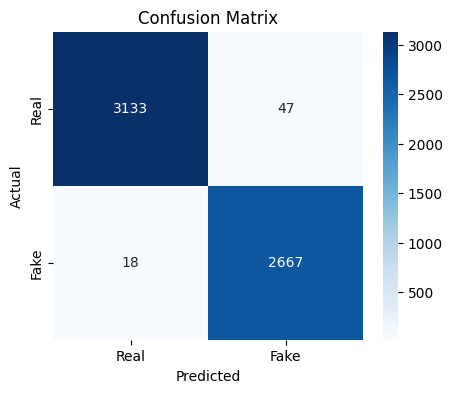

REAL (97%) -> Government announces new budget with higher spending on rural healthcare and education
FAKE (100%) -> SHOCKING: Secret leaked video proves celebrities are hiding the truth about the election


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!pip install -q kagglehub

import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, kagglehub
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

print("GPU:", tf.config.list_physical_devices("GPU"))

# 1. Download dataset
path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")
fake = pd.read_csv(os.path.join(path, "Fake.csv"))
true = pd.read_csv(os.path.join(path, "True.csv"))
fake["label"], true["label"] = 1, 0          # 1 = fake, 0 = real
df = pd.concat([fake, true], ignore_index=True)
print("Articles:", len(df), "| Fake:", int(df.label.sum()), "| Real:", int((df.label == 0).sum()))

# 2. Clean text (remove 'Reuters' tag that leaks the label, drop empties and duplicates)
def clean(t):
    t = re.sub(r"^[^()]{0,60}\(Reuters\)\s*-?\s*", "", str(t))
    t = re.sub(r"\(?Reuters\)?", "", t, flags=re.I)
    t = re.sub(r"http\S+", " ", t)
    return re.sub(r"\s+", " ", t).strip().lower()

df["content"] = (df["title"].fillna("") + ". " + df["text"].fillna("")).apply(clean)
df = df[df["content"].str.len() > 20].drop_duplicates(subset="content").reset_index(drop=True)
print("After cleaning:", len(df))

# 3. Split 70 / 15 / 15
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df["content"].values, df["label"].values, test_size=0.30, stratify=df["label"], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

BATCH = 64
def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if shuffle: ds = ds.shuffle(5000, seed=42)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(X_train, y_train, True), make_ds(X_val, y_val), make_ds(X_test, y_test)

# 4. Model: TextVectorization + Embedding + BiLSTM
VOCAB, SEQ_LEN = 20000, 300
vectorizer = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=SEQ_LEN)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(256))

inp = layers.Input(shape=(), dtype=tf.string)
x = vectorizer(inp)
x = layers.Embedding(VOCAB, 64, mask_zero=True)(x)
x = layers.Bidirectional(layers.LSTM(64))(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(32, activation="relu")(x)
out = layers.Dense(1, activation="sigmoid")(x)
model = Model(inp, out)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

# 5. Train
cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)]
hist = model.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=cb)

# 6. Training curves
plt.figure(figsize=(12, 4))
for i, m in enumerate(["accuracy", "loss"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(hist.history[m], label="train")
    plt.plot(hist.history["val_" + m], label="val")
    plt.title(m); plt.xlabel("epoch"); plt.legend()
plt.show()

# 7. Evaluate on test set
test_loss, test_acc = model.evaluate(test_ds)
y_pred = (model.predict(test_ds).ravel() > 0.5).astype(int)

print("\n===== FINAL TEST RESULTS =====")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred, target_names=["Real", "Fake"], digits=4))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

# 8. Try your own headlines
def predict_news(texts):
    probs = model.predict(tf.constant([clean(t) for t in texts]), verbose=0).ravel()
    for t, p in zip(texts, probs):
        print(f"{'FAKE' if p > 0.5 else 'REAL'} ({max(p, 1 - p):.0%}) -> {t[:90]}")

predict_news([
    "Government announces new budget with higher spending on rural healthcare and education",
    "SHOCKING: Secret leaked video proves celebrities are hiding the truth about the election",
])

# 9. Save and download
model.save("fake_news_model.keras")
from google.colab import files
files.download("fake_news_model.keras")